## Datasci 530 - Assignment 5
### Predicting the 'class' label of Iris plant data

Joelle Millar
November 2026


## Overview

TODO

### Key Findings

TODO

### Set Up, Data Cleaning & Data Descriptions

In [49]:
# Import Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Modules, Functions, Objects
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score


Number of rows: 150
Number of features: 4
Number of classes: 3

Missing values:
Sepal Length    0
Sepal Width     0
Petal Length    0
Petal Width     0
Class           0
dtype: int64


,Count,Proportion
Class,,
Iris-setosa,50,0.333333
Iris-versicolor,50,0.333333
Iris-virginica,50,0.333333


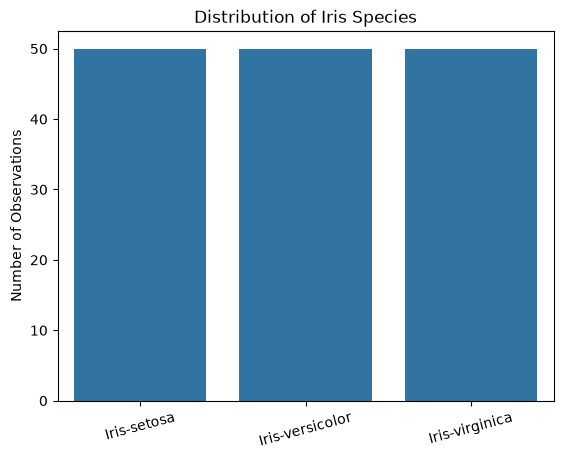

In [47]:
# Load dataset
col_names = [
    'Sepal Length',
    'Sepal Width',
    'Petal Length',
    'Petal Width',
    'Class'
]
iris_data = pd.read_csv(
    "data_raw/iris/iris.data",
    names=col_names
)

# Dataset dimensions
print(f"Number of rows: {iris_data.shape[0]}")
print(f"Number of features: {iris_data.shape[1] - 1}")
print(f"Number of classes: {iris_data['Class'].nunique()}")

# Check missing values
print("\nMissing values:")
print(iris_data.isnull().sum())


# Class distribution
class_distribution = pd.DataFrame({
    'Count': iris_data['Class'].value_counts(),
    'Proportion': iris_data['Class'].value_counts(normalize=True)
})

display(class_distribution)

# Bar Chart for Distribution
sns.countplot(data=iris_data, x='Class')

plt.title('Distribution of Iris Species')
plt.ylabel('Number of Observations')
plt.xlabel('')
plt.xticks(rotation=15)
plt.show()


### Comparison of different ML methods (SVMs, Random Forests, Neural Networks, Ridge)

Prepare the data, separating exploratory variables (X) from the target variable (y) 

In [41]:
# Separate explanatory variables and target
X = iris_data.drop('Class', axis=1)
y = iris_data['Class']

print(f'X shape: {X.shape} | y shape: {y.shape}')

# Split into training and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=1,
    stratify=y
)

print(f'Training observations: {len(X_train)}')
print(f'Testing observations: {len(X_test)}')

X shape: (150, 4) | y shape: (150,)
Training observations: 120
Testing observations: 30


Build the models, using a scaler for SVM and neural networks because they are sensitive to the scale of explanatory variables.

In [44]:
# Define the four models
models = {
    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC())
    ]),

    'Random Forest': RandomForestClassifier(),

    'Neural Network': Pipeline([
        ('scaler', StandardScaler()),
        ('model', MLPClassifier())
    ]),

    'Naive Bayes': GaussianNB()
}

Cross-validation using 10-fold

In [50]:
# Define cross-validation
kfold = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=1
)

# Define evaluation metrics
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision_macro',
    'f1': 'f1_macro'
}

# Evaluate each model
results = []

for name, model in models.items():

    cv_results = cross_validate(
        model,
        X_train,
        y_train,
        cv=kfold,
        scoring=scoring
    )

    results.append({
        'Model': name,
        'Accuracy': cv_results['test_accuracy'].mean(),
        'Accuracy SD': cv_results['test_accuracy'].std(),
        'Precision': cv_results['test_precision'].mean(),
        'F1-score': cv_results['test_f1'].mean()
    })

# Display results
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by='Accuracy',
        ascending=False
    ).round(4)
)

/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/opt/anaconda3/lib/python3.14/site-packages/sklearn/neural_network/_

,Model,Accuracy,Accuracy SD,Precision,F1-score
0,SVM,0.9583,0.0559,0.9650,0.9578
1,Random Forest,0.9500,0.0553,0.9622,0.9484
2,Neural Network,0.9500,0.0553,0.9622,0.9484
3,Naive Bayes,0.9500,0.0764,0.9556,0.9492


Tune the SVM Parameters

In [52]:
# Define SVM pipeline
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('model', SVC())
])

# Define parameter grid
param_grid = {
    'model__C': [0.1, 1, 10, 100],
    'model__gamma': ['scale', 0.01, 0.1, 1]
}

# Grid search using 10-fold cross-validation
svm_grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    cv=kfold,
    scoring='accuracy',
    refit=True,
    n_jobs=-1
)

# Fit grid search
svm_grid.fit(X_train, y_train)

# Display best parameters and score
print("Best parameters:", svm_grid.best_params_)
print("Best cross-validation accuracy:", svm_grid.best_score_)

svm_results = pd.DataFrame(svm_grid.cv_results_)

svm_results = svm_results[
    ['param_model__C',
     'param_model__gamma',
     'mean_test_score',
     'std_test_score',
     'rank_test_score']
].sort_values('rank_test_score')

display(svm_results.round(4))

Best parameters: {'model__C': 1, 'model__gamma': 'scale'}
Best cross-validation accuracy: 0.9583333333333334


,param_model__C,param_model__gamma,mean_test_score,std_test_score,rank_test_score
4,1.0,scale,0.9583,0.0559,1
6,1.0,0.1,0.9500,0.0667,2
7,1.0,1,0.9500,0.0553,2
13,100.0,0.01,0.9500,0.0553,2
14,100.0,0.1,0.9500,0.0553,2
3,0.1,1,0.9417,0.0651,6
9,10.0,0.01,0.9417,0.0651,6
10,10.0,0.1,0.9417,0.0651,6
8,10.0,scale,0.9333,0.0726,9
11,10.0,1,0.9333,0.0726,9


Compare tuned SVM with all the models

In [53]:
# Evaluate the best-performing SVM using the same CV metrics
best_svm_results = cross_validate(
    svm_grid.best_estimator_,
    X_train,
    y_train,
    cv=kfold,
    scoring=scoring
)

# Add tuned SVM results to comparison table
tuned_svm_row = pd.DataFrame([{
    'Model': 'Tuned SVM',
    'Accuracy': best_svm_results['test_accuracy'].mean(),
    'Accuracy SD': best_svm_results['test_accuracy'].std(),
    'Precision': best_svm_results['test_precision'].mean(),
    'F1-score': best_svm_results['test_f1'].mean()
}])

final_results = pd.concat(
    [results_df, tuned_svm_row],
    ignore_index=True
)

display(
    final_results.sort_values(
        by='Accuracy',
        ascending=False
    ).round(4)
)

,Model,Accuracy,Accuracy SD,Precision,F1-score
0,SVM,0.9583,0.0559,0.9650,0.9578
4,Tuned SVM,0.9583,0.0559,0.9650,0.9578
1,Random Forest,0.9500,0.0553,0.9622,0.9484
2,Neural Network,0.9500,0.0553,0.9622,0.9484
3,Naive Bayes,0.9500,0.0764,0.9556,0.9492


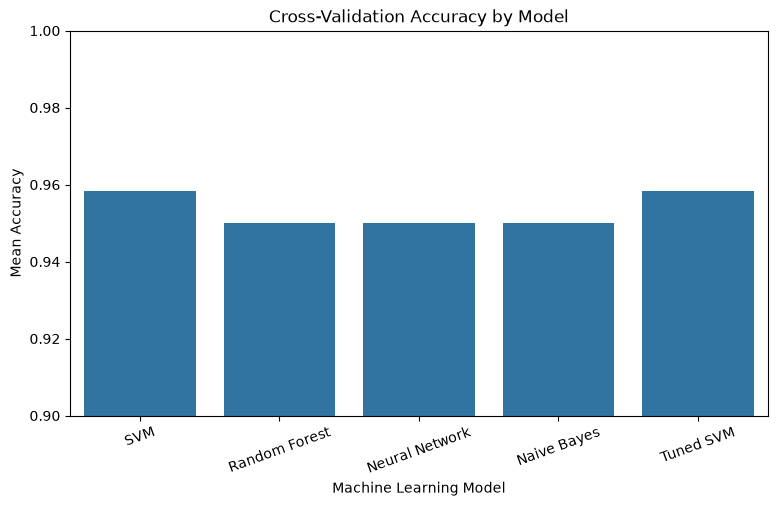

In [56]:
# Compare model accuracy
plt.figure(figsize=(9, 5))

sns.barplot(
    data=final_results,
    x='Model',
    y='Accuracy'
)

plt.title('Cross-Validation Accuracy by Model')
plt.xlabel('Machine Learning Model')
plt.ylabel('Mean Accuracy')
plt.ylim(0.9, 1.0)
plt.xticks(rotation=20)
plt.show()

In [57]:
# Identify best-performing model
best_model_name = final_results.loc[
    final_results['Accuracy'].idxmax(),
    'Model'
]

print("Best-performing model:", best_model_name)

# Select the appropriate model
if best_model_name == 'Tuned SVM':
    best_model = svm_grid.best_estimator_
else:
    best_model = models[best_model_name]

# Fit model on the full training dataset
best_model.fit(X_train, y_train)

# Predict test observations
y_pred = best_model.predict(X_test)

# Evaluate test performance
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Test Accuracy:", accuracy_score(y_test, y_pred))
print("Test Precision:", precision_score(
    y_test, y_pred, average='macro'
))
print("Test Recall:", recall_score(
    y_test, y_pred, average='macro'
))
print("Test F1-score:", f1_score(
    y_test, y_pred, average='macro'
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Best-performing model: SVM
Test Accuracy: 0.9666666666666667
Test Precision: 0.9696969696969697
Test Recall: 0.9666666666666667
Test F1-score: 0.9665831244778613

Classification Report:
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        10
Iris-versicolor       0.91      1.00      0.95        10
 Iris-virginica       1.00      0.90      0.95        10

       accuracy                           0.97        30
      macro avg       0.97      0.97      0.97        30
   weighted avg       0.97      0.97      0.97        30



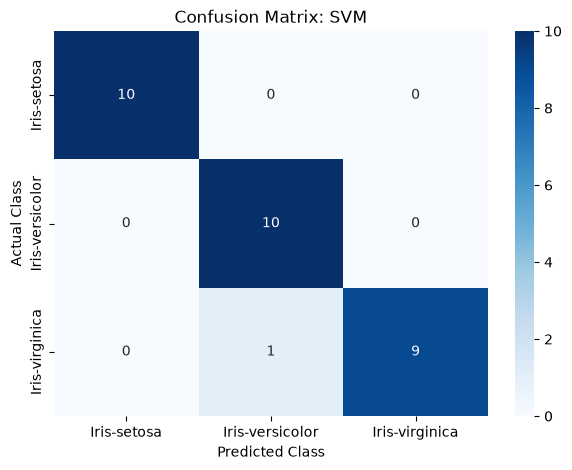

In [58]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=best_model.classes_,
    yticklabels=best_model.classes_
)

plt.title(f'Confusion Matrix: {best_model_name}')
plt.xlabel('Predicted Class')
plt.ylabel('Actual Class')
plt.show()

Random Forest:

Neural Network:

Naive Bayes:

Test the Different Models

TODO
Evaluate the predictive performance using cross-validation.

Consider more than one evaluation metric.

TODO Use the default tuning parameters for all methods except one (you choose). For this method, define a grid of tuning parameters and select the best-performing ones

### Additional Insight

Visualise relationships between the features

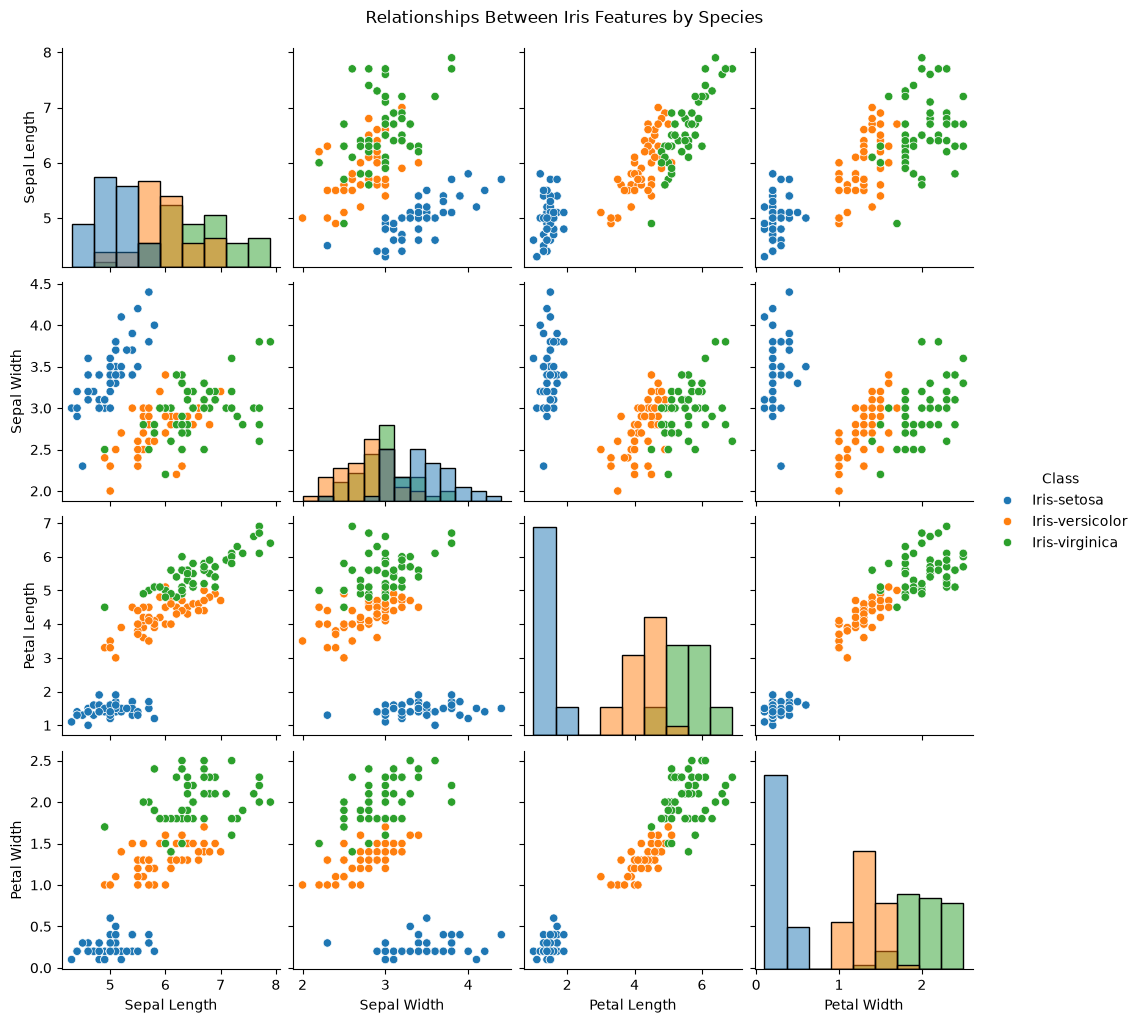

In [59]:
# Pairplot of explanatory variables
sns.pairplot(
    iris_data,
    hue='Class',
    diag_kind='hist'
)

plt.suptitle(
    'Relationships Between Iris Features by Species',
    y=1.02
)

plt.show()